**les imports**

In [3]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

**charger le fichier evenements_clean.csv**

In [4]:
ev = pd.read_csv("../data/processed/evenements_clean.csv")
print(len(ev),(ev["billets_vendus"] == 0).sum())
print(ev.isna().sum())
print(ev.dtypes)

96 0
evenement_id         0
genre                0
jour_semaine         0
capacite             0
prix_moyen_eur       0
notoriete_artiste    0
billets_vendus       3
date                 0
taux_remplissage     3
dtype: int64
evenement_id             str
genre                    str
jour_semaine             str
capacite               int64
prix_moyen_eur       float64
notoriete_artiste    float64
billets_vendus       float64
date                     str
taux_remplissage     float64
dtype: object


**reperer les 3 evenements**

In [5]:
print(ev[ev["billets_vendus"].isna()]["evenement_id"].tolist())

['EV374', 'EV303', 'EV355']


**les retirer et corriger le type**

In [6]:
ev = ev.dropna(subset=["billets_vendus"]).copy()
ev["billets_vendus"] = ev["billets_vendus"].astype(int)
print(len(ev), ev["billets_vendus"].dtype)

93 int64


**vérifier la colonne taux_remplissage de Fourkhoub**

In [7]:
verif = ev["billets_vendus"] / ev["capacite"]
print((verif - ev["taux_remplissage"]).abs().max())
print(ev["taux_remplissage"].isna().sum())
print(ev["taux_remplissage"].describe().round(3))

0.0
0
count    93.000
mean      0.584
std       0.199
min       0.235
25%       0.427
50%       0.558
75%       0.691
max       1.000
Name: taux_remplissage, dtype: float64


**creer la colonne mois**

In [8]:
ev["mois"] = pd.to_datetime(ev["date"]).dt.month
print(ev["mois"].value_counts().sort_index())

mois
1      8
2      7
3      7
4      7
5      8
6      6
7      8
8      8
9     11
10     8
11     7
12     8
Name: count, dtype: int64


transformer la date en un numéro de mois (1 à 12), pour pouvoir regrouper les événements par saison.

**le taux moyen par mois avec un graphique**

      count   mean    std
mois                     
1         8  0.499  0.212
2         7  0.581  0.225
3         7  0.674  0.173
4         7  0.479  0.099
5         8  0.601  0.215
6         6  0.458  0.108
7         8  0.668  0.229
8         8  0.587  0.236
9        11  0.584  0.185
10        8  0.495  0.145
11        7  0.686  0.203
12        8  0.670  0.235


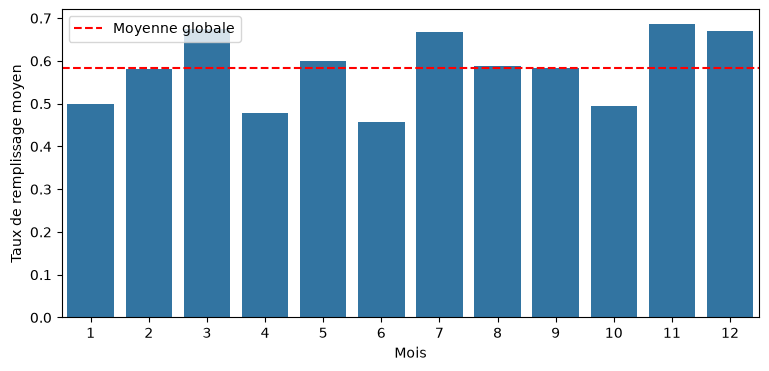

In [9]:
par_mois = ev.groupby("mois")["taux_remplissage"].agg(["count", "mean", "std"]).round(3)
print(par_mois)

plt.figure(figsize=(9, 4)) 
sns.barplot(x=par_mois.index, y=par_mois["mean"])
plt.axhline(ev["taux_remplissage"].mean(), color="red", linestyle="--", label="Moyenne globale")
plt.xlabel("Mois")
plt.ylabel("Taux de remplissage moyen")
plt.legend()
plt.show()

In [10]:
from scipy import stats
groupes = [g["taux_remplissage"].values for _, g in ev.groupby("mois")]
stat, p = stats.f_oneway(*groupes)
print(round(stat, 2), round(p, 3))

1.28 0.253


Le remplissage moyen varie de 46 % (juin) à 69 % (novembre), mais l'écart entre mois n'est pas significatif (ANOVA : F = 1,28, p = 0,25, supérieur à 0,05), avec seulement 6 à 11 événements par mois. Limite : le mois est tiré de date, qui est incohérente avec jour_semaine pour 81 événements sur 98, donc peu fiable. Je le teste dans le modèle et je l'écarterai s'il n'apporte rien.

**le taux moyen par genre**

In [11]:
print(ev.groupby("genre")["taux_remplissage"].agg(["count", "mean", "std"]).round(3))

             count   mean    std
genre                           
concert pop     26  0.572  0.187
humour           9  0.617  0.233
rap             14  0.572  0.163
rock            23  0.523  0.176
spectacle        8  0.617  0.251
sport           13  0.682  0.232


Le sport est le genre le mieux rempli (68 %), le rock le moins (52 %). Spectacle (8 événements) et humour (9 événements) sont peu représentés : leurs moyennes sont fragiles. Le genre est une variable utile, et ce faible effectif annonce la difficulté de Q4 : il sera difficile d'estimer l'erreur de prévision sur ces genres.

**les corrélations avec le taux**

In [12]:
print(ev[["taux_remplissage", "notoriete_artiste", "prix_moyen_eur"]].corr().round(2)["taux_remplissage"])

taux_remplissage     1.00
notoriete_artiste    0.53
prix_moyen_eur      -0.29
Name: taux_remplissage, dtype: float64


La notoriété de l'artiste est nettement liée au remplissage (+0,53) : plus il est connu, plus la salle se remplit. Le prix est lié négativement de façon modérée (−0,29). Une corrélation n'est pas une cause : la régression séparera les effets. La capacité n'a que 3 valeurs, je la traite comme une catégorie

**le taux selon la capacité**

In [13]:
ev["capacite_cat"] = ev["capacite"].astype(str)
print(ev.groupby("capacite_cat")["taux_remplissage"].agg(["count", "mean"]).round(3))

groupes = [g["taux_remplissage"].values for _, g in ev.groupby("capacite_cat")]
stat, p = stats.f_oneway(*groupes)
print(round(stat, 2), p)

              count   mean
capacite_cat              
15800            25  0.447
6500             27  0.746
9800             41  0.560
22.01 1.6555078625054242e-08


Une salle de 6 500 places se remplit à 75 %, une salle de 9 800 à 56 %, une salle de 15 800 à 45 %. L'écart est très significatif (F = 22, p inférieur à 0,001). La capacité est traitée comme une catégorie. Cela justifie de prédire le taux de remplissage et non le nombre de billets, car la taille de la salle masquerait l'effet de la popularité.

In [14]:
print("------------------------------------------------------------------------------")

------------------------------------------------------------------------------


**modéle**

In [15]:
import os
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

cat = ["genre", "jour_semaine", "capacite_cat"]
num = ["prix_moyen_eur", "notoriete_artiste"]
X = ev[cat + num]
y = ev["taux_remplissage"]

Les variables sont celles connues à J-90 : genre, jour, capacité (en catégorie), prix, notoriété. billets_vendus et le fichier billets sont exclus pour éviter toute fuite de données.

**le pipeline**

but : mettre les donnees dans un format lisible par le modèle , sans tricher avec les données de test 

In [16]:
def construire(modele, colonnes_num=num, standardiser=False):
    etapes_num = [("imp", SimpleImputer(strategy="median"))]
    if standardiser:
        etapes_num.append(("std", StandardScaler()))
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ("num", Pipeline(etapes_num), colonnes_num)])
    return Pipeline([("prep", prep), ("modele", modele)])

Le pipeline transforme les catégories en 0/1, impute par la médiane et enchaîne avec le modèle. Ces traitements sont refaits dans chaque pli de la validation croisée, ce qui évite la fuite de données.

**comparaison des_modeles**

In [17]:
def evaluer(modele, X, graines=range(30)):
    maes, rmses, r2s = [], [], []
    for g in graines:
        cv = KFold(n_splits=5, shuffle=True, random_state=g)
        pred = cross_val_predict(modele, X, y, cv=cv)
        err = y - pred
        maes.append(err.abs().mean())
        rmses.append(np.sqrt((err ** 2).mean()))
        r2s.append(1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum())
    return round(float(np.mean(maes)), 3), round(float(np.mean(rmses)), 3), round(float(np.mean(r2s)), 3)

print("Référence", evaluer(construire(DummyRegressor(strategy="mean")), X))
print("Linéaire ", evaluer(construire(LinearRegression()), X))
for k in [3, 5, 7, 10]:
    print("KNN", k, evaluer(construire(KNeighborsRegressor(n_neighbors=k), standardiser=True), X))

Référence (0.163, 0.201, -0.028)
Linéaire  (0.089, 0.111, 0.685)
KNN 3 (0.111, 0.142, 0.486)
KNN 5 (0.11, 0.139, 0.51)
KNN 7 (0.114, 0.142, 0.484)
KNN 10 (0.118, 0.147, 0.448)


En validation croisée (5 plis, 30 répétitions), la régression linéaire réduit l'erreur moyenne de 0,163 à 0,089 par rapport à la prévision par la moyenne, et explique 68 % de la variation (R² = 0,68). Elle est meilleure que le KNN (meilleur cas : MAE 0,110, R² = 0,51). Je retiens la régression linéaire : la plus précise avec 93 événements, et interprétable. Les 32 % restants ne s'expliquent pas par les variables connues à J-90 : d'où la fourchette.

**le mois améliore-t-il la prévision ?**

In [18]:
X_mois = ev[cat + num + ["mois"]]
print("Linéaire + mois", evaluer(construire(LinearRegression(), colonnes_num=num + ["mois"]), X_mois))

Linéaire + mois (0.091, 0.114, 0.672)


Ajouter le mois dégrade légèrement la prévision (MAE 0,091 contre 0,089). Il n'est pas significatif (p = 0,25) et vient d'une date incohérente avec jour_semaine. Je l'écarte du modèle.

In [19]:
print("------------------------------------------------------------------------------")

------------------------------------------------------------------------------


**Q3:conclure**

**les erreurs hors échantillon et la marge**
But : mesurer de combien on se trompe, pour transformer l'imprévisible en marge chiffrée.

In [20]:
modele = construire(LinearRegression())
lignes = []
for g in range(30):
    cv = KFold(n_splits=5, shuffle=True, random_state=g)
    pred = cross_val_predict(modele, X, y, cv=cv)
    lignes.append(pd.DataFrame({"evenement_id": ev["evenement_id"], "genre": ev["genre"],
                                "erreur": y - pred, "graine": g}))
erreurs = pd.concat(lignes)
q10, q90 = erreurs["erreur"].quantile([0.10, 0.90])
print(erreurs.shape, round(q10, 3), round(q90, 3))

(2790, 4) -0.145 0.142


Les erreurs hors échantillon (2 790 prédictions, 30 découpages) donnent une marge à 80 % de −14,5 à +14,2 points de remplissage autour de la prévision.

**annoncer un nombre de billets avec sa fourchette**

répondre directement à Q3 : un nombre pour le producteur, avec sa marge.

In [21]:
final = construire(LinearRegression()).fit(X, y)

def annoncer(genre, jour, capacite, prix, notoriete):
    ligne = pd.DataFrame([{"genre": genre, "jour_semaine": jour, "capacite_cat": str(capacite),
                           "prix_moyen_eur": prix, "notoriete_artiste": notoriete}])
    taux = float(np.clip(final.predict(ligne)[0], 0, 1))
    bas = float(np.clip(taux + q10, 0, 1))
    haut = float(np.clip(taux + q90, 0, 1))
    return round(taux * capacite), round(bas * capacite), round(haut * capacite)

print(annoncer("rock", "sam", 9800, 70, 40))
print(annoncer("sport", "sam", 15800, 70, 60))
print(annoncer("rap", "ven", 6500, 50, 30))

(5889, 4470, 7279)
(8668, 6379, 10908)
(4354, 3412, 5276)


Q3. Pour annoncer au producteur, on calcule le taux de remplissage prévu à partir des seules informations connues à J-90, puis on le multiplie par la capacité. La marge à 80 % est de −14,5 à +14,2 points, soit environ −1 400 à +1 400 billets pour une salle de 9 800 places. Exemple : un rock un samedi dans une salle de 9 800 places, à 70 € et notoriété 40 → environ 5 900 billets, entre 4 500 et 7 300. Décision : ne jamais annoncer un chiffre seul, toujours une fourchette. Le modèle explique 68 % du remplissage ; le reste est imprévisible à J-90.

**graphique réel contre prévu**

But : un graphique pour les slides qui montre la qualité de la prévision.

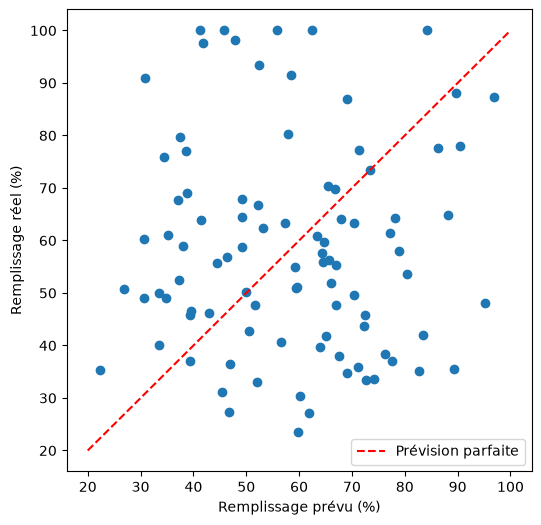

In [22]:
par_event = erreurs.groupby("evenement_id").agg(genre=("genre", "first"), erreur=("erreur", "mean"))
reel = ev.set_index("evenement_id")["taux_remplissage"]
prevu = reel - par_event["erreur"]

os.makedirs("../docs/figures", exist_ok=True)
plt.figure(figsize=(6, 6))
plt.scatter(prevu * 100, reel * 100)
plt.plot([20, 100], [20, 100], "r--", label="Prévision parfaite")
plt.xlabel("Remplissage prévu (%)")
plt.ylabel("Remplissage réel (%)")
plt.legend()
plt.savefig("../docs/figures/q3_reel_vs_prevu.png", dpi=200, bbox_inches="tight")
plt.show()

Les points suivent la diagonale (prévision parfaite) avec une dispersion d'environ 10 points : le modèle capte la tendance mais pas le détail de chaque événement.